In [3]:
# Импорт необходимых библиотек для ML
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import precision_score, roc_auc_score
from sklearn.metrics import recall_score, roc_curve
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from imblearn.over_sampling import SMOTE # для борьбы с дисбалансом
from imblearn.pipeline import Pipeline as ImbPipeline

In [4]:
#Предустановка и импорт библиотек для DL
!pip install tensorflow
!pip install keras
!pip install scikeras
!pip install optuna -q

import tensorflow as tf
import optuna
from tensorflow import keras
from tensorflow.keras import layers, models
from scikeras.wrappers import KerasClassifier
from optuna.pruners import MedianPruner


In [5]:
#Загрузка данных (первые 5 строк)
#df = pd.read_csv('/content/churn-bigml-20.csv')
df = pd.read_csv('/content/Dataset_telecom.csv')
print("Исходный размер df:", df.shape)
print("\nПервые 5 строк:")
df.head()

Исходный размер df: (667, 20)

Первые 5 строк:


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


In [6]:
#Информация о данных
print("Информация о данных:")
df.info()
print(f"\nКоличество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
print("\nСтатистика по числовым признакам:")
print(df.describe())
print("\nПропуски в данных:")
print(df.isnull().sum())

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    object 
 4   Voice mail plan         667 non-null    object 
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge   

#Предобработка.

In [7]:
# Удаление пропусков при их наличии
if df.isnull().sum().any():
    df = df.fillna(df.median())
    print("\nПропуски заполнены медианами")
else:
    print("\nПропуски отсутствуют")


Пропуски отсутствуют


Распределение целевой переменной Churn:
Churn
False    572
True      95
Name: count, dtype: int64

Доля оттока:
Churn
False    0.857571
True     0.142429
Name: proportion, dtype: float64


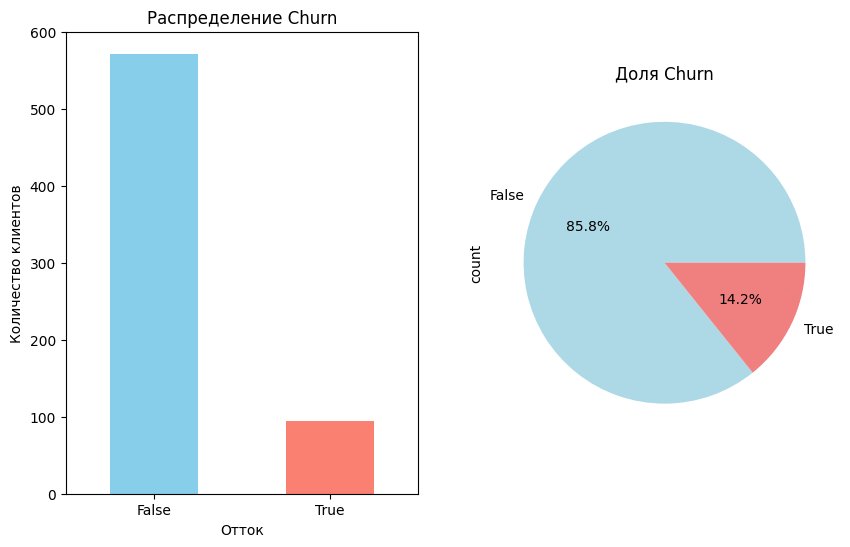

In [8]:
# Анализ целевой переменной 'Churn'
print("Распределение целевой переменной Churn:")
print(df['Churn'].value_counts())
print("\nДоля оттока:")
print(df['Churn'].value_counts(normalize=True))

# Визуализация распределения целевой переменной
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
df['Churn'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Распределение Churn')
plt.xlabel('Отток')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
df['Churn'].value_counts().plot(kind='pie', autopct='%1.1f%%',
 colors=['lightblue', 'lightcoral'])
plt.title('Доля Churn')
plt.show()

In [9]:
#Перевод категориальных признаков в числовые.
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Категориальные колонки: {cat_cols}")

Категориальные колонки: ['State', 'International plan', 'Voice mail plan']


In [10]:
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    print(f"Закодирован признак: {col}")

print("\nДанные после кодирования:")
print(df.head())

Закодирован признак: State
Закодирован признак: International plan
Закодирован признак: Voice mail plan

Данные после кодирования:
   State  Account length  Area code  International plan  Voice mail plan  \
0     18             117        408                   0                0   
1     15              65        415                   0                0   
2     34             161        415                   0                0   
3     40             111        415                   0                0   
4     11              49        510                   0                0   

   Number vmail messages  Total day minutes  Total day calls  \
0                      0              184.5               97   
1                      0              129.1              137   
2                      0              332.9               67   
3                      0              110.4              103   
4                      0              119.3              117   

   Total day charge  Total 

In [11]:
# Преобразование целевой переменной
df['Churn'] = df['Churn'].astype(bool).astype(int)
print(f"\nЦелевая переменная преобразована: {df['Churn'].value_counts().to_dict()}")


Целевая переменная преобразована: {0: 572, 1: 95}


In [12]:
# Разделяем на признаки и целевую переменную.Целевая переменная - 'Churn'
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape, X_test.shape)
print(f"Обучающая выборка: {X_train.shape[0]} примеров")
print(f"Тестовая выборка: {X_test.shape[0]} примеров")

(533, 19) (134, 19)
Обучающая выборка: 533 примеров
Тестовая выборка: 134 примеров


In [13]:
# Анализ дисбаланса
print("Распределение классов до балансировки (SMOTE):")
print(y_train.value_counts())
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("\nРаспределение классов после SMOTE:")
print(y_train_balanced.value_counts())

Распределение классов до балансировки (SMOTE):
Churn
0    457
1     76
Name: count, dtype: int64

Распределение классов после SMOTE:
Churn
0    457
1    457
Name: count, dtype: int64


In [14]:
# Масштабирование данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

print("\nМасштабированные признаки (первые 5 строк):")
print(X_train_scaled[:5])
print(f"\nТип данных X_train_scaled: {type(X_train_scaled)}")
print(f"Форма X_train_scaled: {X_train_scaled.shape}")


Масштабированные признаки (первые 5 строк):
      State  Account length  Area code  International plan  Voice mail plan  \
0  0.405689        2.009375  -0.525522           -0.278981         2.239008   
1 -1.339071        0.078008  -0.690900           -0.278981         2.239008   
2 -0.883916        0.024359  -0.690900           -0.278981        -0.446626   
3  1.391857        0.480376  -0.525522           -0.278981        -0.446626   
4  0.329829        0.641324   1.718887           -0.278981        -0.446626   

   Number vmail messages  Total day minutes  Total day calls  \
0               2.412979          -0.323137        -0.638612   
1               2.161032          -0.472948         1.305832   
2              -0.526406           1.332666         1.357001   
3              -0.526406          -0.974420         0.589458   
4              -0.526406           0.692422         0.333610   

   Total day charge  Total eve minutes  Total eve calls  Total eve charge  \
0         -0.32299

#ПОДБОР ГИПЕРПАРАМЕТРОВ С GRIDSEARCHCV

In [15]:
#Выбор моделей и подбор гиперпараметров для каждой с GRIDSEARCHCV
models = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=5000, random_state=42),
        'params': {
            'C': [0.1, 1, 10, 100],
            'penalty': ['l1', 'l2'],
            'solver': ['liblinear', 'saga']
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [5, 15, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    'SVM': {
        'model': SVC(probability=True, random_state=42),
        'params': {
            'C': [0.1, 1, 10],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto']
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'learning_rate': [0.05, 0.1, 0.15],
            'max_depth': [3, 4, 5]
        }
    }
}

results = []
best_models = {}

# Обучение и подбор гиперпараметров для каждой модели
for name, config in models.items():
    print(f"\n--- Подбор параметров для {name} ---")

    # Выбираем масштабированные данные для линейных моделей обычные для tree-based
    if name in ['Logistic Regression', 'SVM']:
        X_train_model = X_train_scaled
        X_test_model = X_test_scaled
    else:
        X_train_model = X_train_balanced
        X_test_model = X_test

    # Подбор гиперпараметров
    grid_search = GridSearchCV(
        config['model'],
        config['params'],
        cv=5,
        scoring='f1',
        n_jobs=-1,
        verbose=1
    )
    grid_search.fit(X_train_model, y_train_balanced)

    # Сохраняем лучшую модель
    best_models[name] = grid_search.best_estimator_

    # Предсказания
    y_pred = best_models[name].predict(X_test_model)
    y_prob = best_models[name].predict_proba(X_test_model)[:, 1]

    # Вычисляем метрики
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

    print(f"Лучшие параметры: {grid_search.best_params_}")
    print(f"Лучший F1: {grid_search.best_score_:.4f}")
    print(f"Тестовый F1: {f1:.4f}")


--- Подбор параметров для Logistic Regression ---
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Лучшие параметры: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Лучший F1: 0.7959
Тестовый F1: 0.5200

--- Подбор параметров для Random Forest ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Лучшие параметры: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
Лучший F1: 0.9577
Тестовый F1: 0.6875

--- Подбор параметров для SVM ---
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Лучшие параметры: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Лучший F1: 0.9449
Тестовый F1: 0.5294

--- Подбор параметров для Gradient Boosting ---
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Лучшие параметры: {'learning_rate': 0.15, 'max_depth': 5, 'n_estimators': 100}
Лучший F1: 0.9561
Тестовый F1: 0.7059


In [19]:
# Сводная таблица результатов ML моделей
print("\n" + "="*63)
print("               СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ ML МОДЕЛЕЙ")
print("="*63)

# Создаем список только ML моделей (исключаем нейронную сеть). Ранее Итоговая таблица была только в конце с ML и DL, но для наглядности и для презентации вывела дополнительно таблицу только по ML
ml_models = ['Logistic Regression', 'Random Forest', 'SVM', 'Gradient Boosting']
ml_results = [result for result in results if result['Model'] in ml_models]

ml_results_df = pd.DataFrame(ml_results)
# Сортируем модели по F1-Score по убыванию
ml_results_df = ml_results_df.sort_values('F1-Score', ascending=False)

# Форматируем числа для красивого вывода
formatted_ml_results = ml_results_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']:
    formatted_ml_results[col] = formatted_ml_results[col].apply(lambda x: f'{x:.4f}')

# Выводим таблицу ML моделей
print(formatted_ml_results.to_string(index=False))


               СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ ML МОДЕЛЕЙ
              Model Accuracy Precision Recall F1-Score ROC-AUC
  Gradient Boosting   0.9254    0.8000 0.6316   0.7059  0.8847
      Random Forest   0.9254    0.8462 0.5789   0.6875  0.8902
                SVM   0.8806    0.6000 0.4737   0.5294  0.8430
Logistic Regression   0.8209    0.4194 0.6842   0.5200  0.7968


#Простая нейронная сеть (полносвязная) FCNN

In [20]:
def build_hidden_layers(trial):
    """Функция для построения скрытых слоев нейронной сети"""
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_units = []
    for i in range(n_layers):
        hidden_units.append(trial.suggest_int(f"n_units_l{i}", 64, 512, step=64))
    return hidden_units

def objective(trial):
    """Целевая функция для Optuna"""
    # Подбор гиперпараметров
    activation = trial.suggest_categorical("activation", ["relu", "tanh"])
    use_bn = trial.suggest_categorical("use_batchnorm", [True, False])
    dropout_p = trial.suggest_float("dropout_p", 0.0, 0.6)
    hidden_units = build_hidden_layers(trial)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])

    # Создание модели
    model = tf.keras.Sequential()

    # Входной слой
    model.add(tf.keras.layers.Dense(hidden_units[0], activation=activation,
                                   input_shape=(X_train_scaled.shape[1],)))
    if use_bn:
        model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.Dropout(dropout_p))

    # Скрытые слои
    for units in hidden_units[1:]:
        model.add(tf.keras.layers.Dense(units, activation=activation))
        if use_bn:
            model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Dropout(dropout_p))

    # Выходной слой
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    # Компиляция модели
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )

    # Callbacks
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=0
    )

    # Короткое обучение для быстрого поиска
    EPOCHS = 50

    # Обучение модели
    history = model.fit(
        X_train_scaled, y_train_balanced,
        batch_size=batch_size,
        epochs=EPOCHS,
        validation_data=(X_test_scaled, y_test),
        callbacks=[early_stopping],
        verbose=0
    )

    # Оценка качества
    y_pred = (model.predict(X_test_scaled, verbose=0) > 0.5).astype(int).flatten()
    val_f1 = f1_score(y_test, y_pred)

    # Отчет для pruner
    best_epoch = np.argmin(history.history['val_loss'])
    trial.report(val_f1, best_epoch)

    # Pruning если trial безнадежен
    if trial.should_prune():
        raise optuna.exceptions.TrialPruned()

    return val_f1

# Создаем study с pruner
study = optuna.create_study(
    direction="maximize",
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=3)
)

print("Запускаем исследование Optuna (20 испытаний)...")
study.optimize(objective, n_trials=20)

# Результаты
print("\n" + "="*40)
print("          РЕЗУЛЬТАТЫ OPTUNA")
print("="*40)
print(f"Лучшее значение F1-score: {study.best_value:.4f}")
print("Лучшие параметры:")
for k, v in study.best_trial.params.items():
    print(f"  {k}: {v}")

[I 2025-10-14 12:26:43,471] A new study created in memory with name: no-name-44b711a0-f615-4eb5-8c0a-3ca4110ba0aa
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Запускаем исследование Optuna (20 испытаний)...


[I 2025-10-14 12:26:56,187] Trial 0 finished with value: 0.5714285714285714 and parameters: {'activation': 'tanh', 'use_batchnorm': True, 'dropout_p': 0.5041050243929118, 'n_layers': 2, 'n_units_l0': 320, 'n_units_l1': 320, 'lr': 0.0018281609064118678, 'batch_size': 32}. Best is trial 0 with value: 0.5714285714285714.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
[I 2025-10-14 12:27:06,426] Trial 1 finished with value: 0.46153846153846156 and parameters: {'activation': 'tanh', 'use_batchnorm': True, 'dropout_p': 0.5083948670412929, 'n_layers': 2, 'n_units_l0': 128, 'n_units_l1': 256, 'lr': 0.0002809495447421328, 'batch_size': 32}. Best is trial 0 with value: 0.5714285714285714.
/usr/local/lib/python3.12/di


РЕЗУЛЬТАТЫ OPTUNA
Лучшее значение F1-score: 0.6667
Лучшие параметры:
  activation: relu
  use_batchnorm: False
  dropout_p: 0.16642724199194064
  n_layers: 1
  n_units_l0: 320
  lr: 0.0008609101475550798
  batch_size: 64


In [26]:
# Визуализация результатов Optuna (процесса оптимизации)
fig = optuna.visualization.plot_optimization_history(study)
fig.show()
fig = optuna.visualization.plot_param_importances(study)
fig.show()


In [27]:
# Функция для создания финальной модели с лучшими параметрами
def create_final_model(best_params):
    """Создание финальной модели с лучшими параметрами"""
    model = tf.keras.Sequential()

    # Восстанавливаем архитектуру из лучших параметров
    hidden_units = []
    n_layers = best_params['n_layers']
    for i in range(n_layers):
        hidden_units.append(best_params[f'n_units_l{i}'])

    # Входной слой
    model.add(tf.keras.layers.Dense(
        hidden_units[0],
        activation=best_params['activation'],
        input_shape=(X_train_scaled.shape[1],)
    ))
    if best_params['use_batchnorm']:
        model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.Dropout(best_params['dropout_p']))

    # Скрытые слои
    for units in hidden_units[1:]:
        model.add(tf.keras.layers.Dense(units, activation=best_params['activation']))
        if best_params['use_batchnorm']:
            model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Dropout(best_params['dropout_p']))

    # Выходной слой
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    # Компиляция
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=best_params['lr']),
        loss='binary_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )

    return model

# Создаем и обучаем финальную модель
print("\nСоздание и обучение финальной модели с лучшими параметрами...")
best_nn_model = create_final_model(study.best_params)

# Callbacks для финального обучения
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-7,
        verbose=1
    )
]

# Обучение финальной модели
history = best_nn_model.fit(
    X_train_scaled, y_train_balanced,
    batch_size=study.best_params['batch_size'],
    epochs=150,
    validation_data=(X_test_scaled, y_test),
    callbacks=callbacks,
    verbose=1
)

# Предсказания и метрики
y_pred_nn = (best_nn_model.predict(X_test_scaled) > 0.5).astype(int).flatten()
y_prob_nn = best_nn_model.predict(X_test_scaled).flatten()

# Вычисляем метрики
accuracy_nn = accuracy_score(y_test, y_pred_nn)
precision_nn = precision_score(y_test, y_pred_nn)
recall_nn = recall_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn)
roc_auc_nn = roc_auc_score(y_test, y_prob_nn)

print(f"\nФинальные метрики нейронной сети:")
print(f"Accuracy:  {accuracy_nn:.4f}")
print(f"Precision: {precision_nn:.4f}")
print(f"Recall:    {recall_nn:.4f}")
print(f"F1-Score:  {f1_nn:.4f}")
print(f"ROC-AUC:   {roc_auc_nn:.4f}")


Создание и обучение финальной модели с лучшими параметрами...
Epoch 1/150


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - Precision: 0.5050 - Recall: 0.4693 - accuracy: 0.5154 - loss: 0.6920 - val_Precision: 0.3333 - val_Recall: 0.6316 - val_accuracy: 0.7687 - val_loss: 0.5873 - learning_rate: 8.6091e-04
Epoch 2/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - Precision: 0.7465 - Recall: 0.7462 - accuracy: 0.7415 - loss: 0.5716 - val_Precision: 0.3824 - val_Recall: 0.6842 - val_accuracy: 0.7985 - val_loss: 0.5091 - learning_rate: 8.6091e-04
Epoch 3/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - Precision: 0.7710 - Recall: 0.7931 - accuracy: 0.7842 - loss: 0.5014 - val_Precision: 0.4054 - val_Recall: 0.7895 - val_accuracy: 0.8060 - val_loss: 0.4664 - learning_rate: 8.6091e-04
Epoch 4/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - Precision: 0.7827 - Recall: 0.8322 - accuracy: 0.8117 - loss: 0.4624 - val_Precision: 0.4242 - val_Recall: 0.7368 - val_accuracy: 0.8209 - val_loss: 0.4322 - learning_rate: 8.6091e-04
Epoch 5/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - Precision:

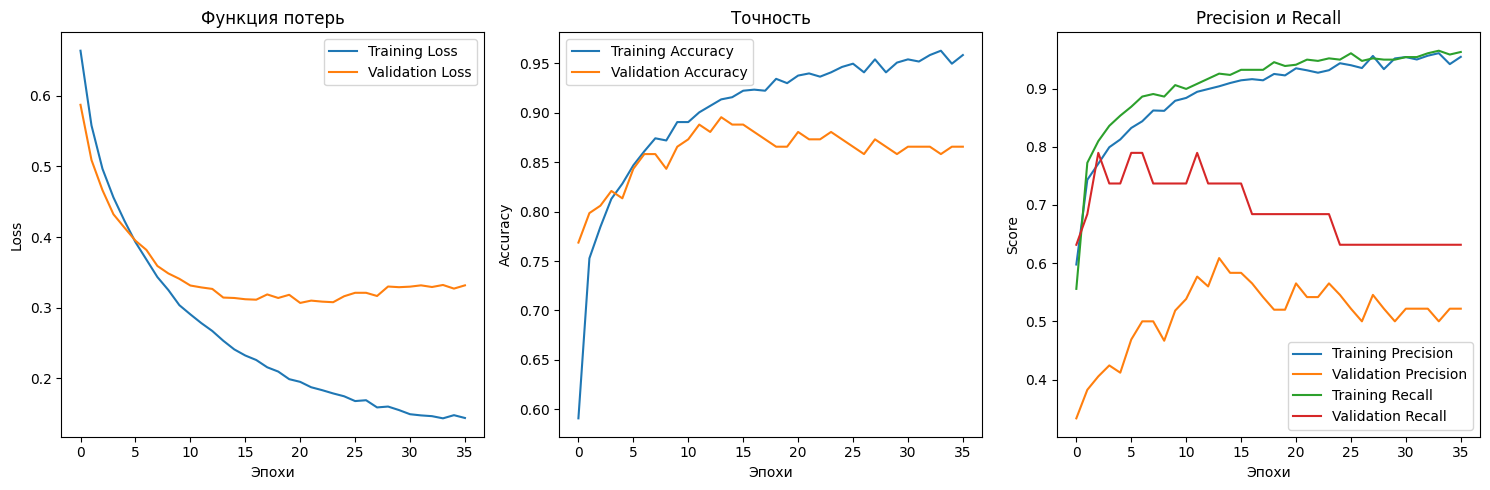

In [28]:
# Визуализация обучения финальной модели
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Функция потерь')
plt.xlabel('Эпохи')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Точность')
plt.xlabel('Эпохи')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history.history['Precision'], label='Training Precision')
plt.plot(history.history['val_Precision'], label='Validation Precision')
plt.plot(history.history['Recall'], label='Training Recall')
plt.plot(history.history['val_Recall'], label='Validation Recall')
plt.title('Precision и Recall')
plt.xlabel('Эпохи')
plt.ylabel('Score')
plt.legend()

plt.tight_layout()
plt.show()

# Добавляем результаты нейронной сети в общую таблицу
results.append({
    'Model': 'Нейронная сеть (Optuna)',
    'Accuracy': accuracy_nn,
    'Precision': precision_nn,
    'Recall': recall_nn,
    'F1-Score': f1_nn,
    'ROC-AUC': roc_auc_nn
})

#Сравнение и оценка моделей

In [29]:
#Сравнение и оценка моделей

# Создаем DataFrame с результатами
results_df = pd.DataFrame(results)

print("\n" + "="*70)
print("                      СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("="*70)
print(results_df.round(4))




                      СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
                     Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0      Logistic Regression    0.8209     0.4194  0.6842    0.5200   0.7968
1            Random Forest    0.9254     0.8462  0.5789    0.6875   0.8902
2                      SVM    0.8806     0.6000  0.4737    0.5294   0.8430
3        Gradient Boosting    0.9254     0.8000  0.6316    0.7059   0.8847
4  Нейронная сеть (Optuna)    0.8806     0.5652  0.6842    0.6190   0.8650


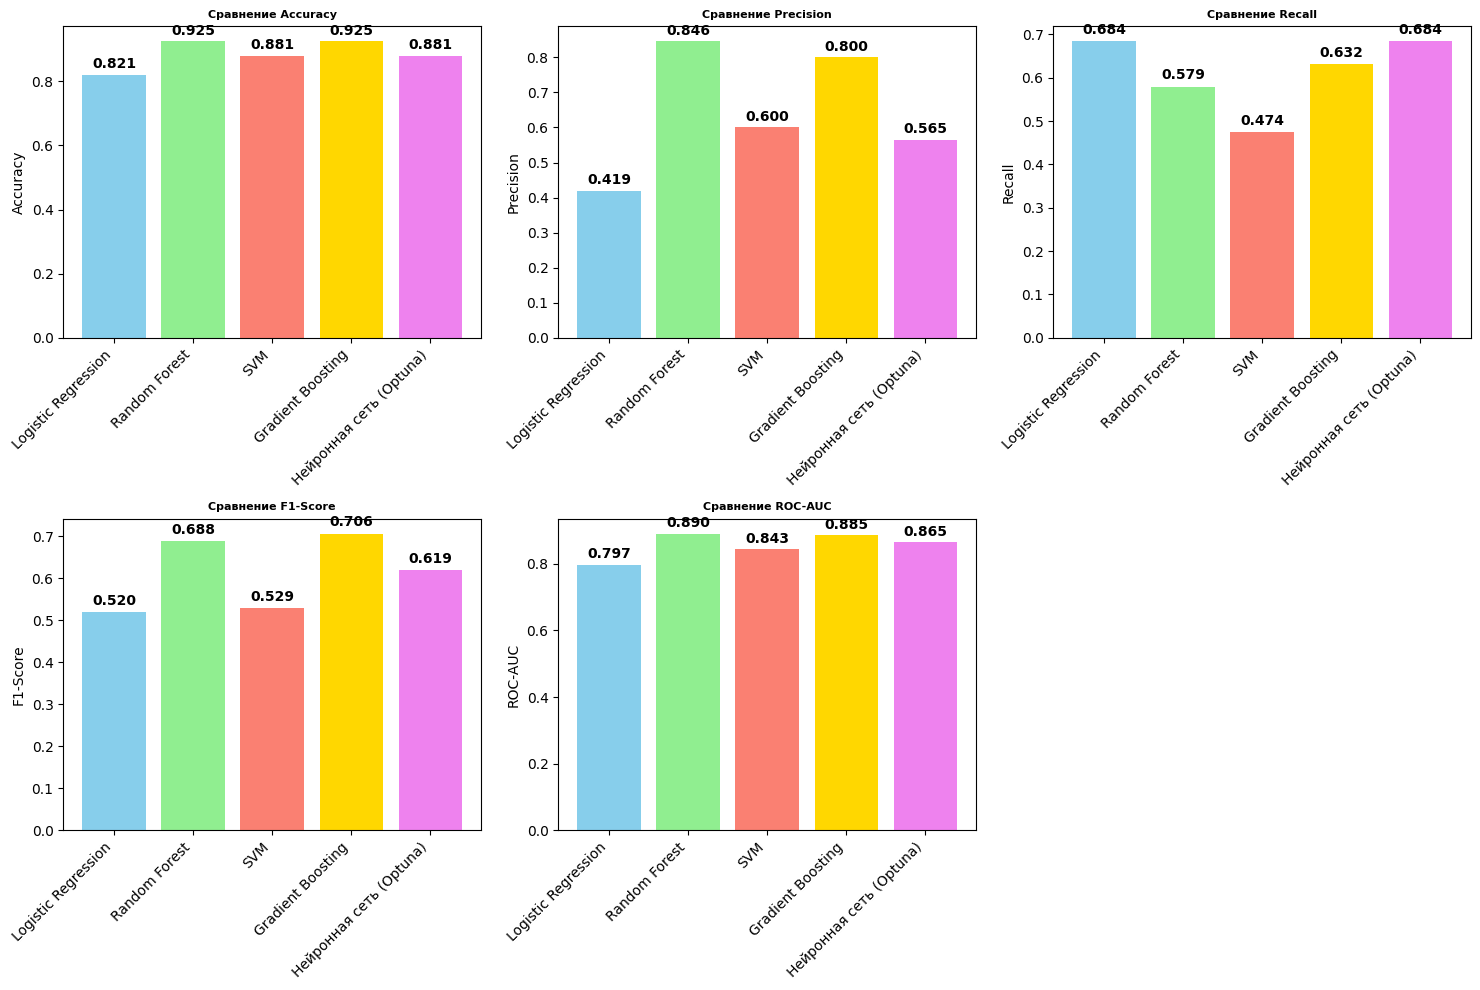

In [30]:
# Визуализация сравнения метрик
plt.figure(figsize=(15, 10))
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

for i, metric in enumerate(metrics_to_plot, 1):
    plt.subplot(2, 3, i)
    bars = plt.bar(results_df['Model'], results_df[metric],
                   color=['skyblue', 'lightgreen', 'salmon', 'gold', 'violet', 'orange'])
    plt.title(f'Сравнение {metric}', fontsize=8, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.ylabel(metric)

    # Добавляем значения на столбцы
    for bar, v in zip(bars, results_df[metric]):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


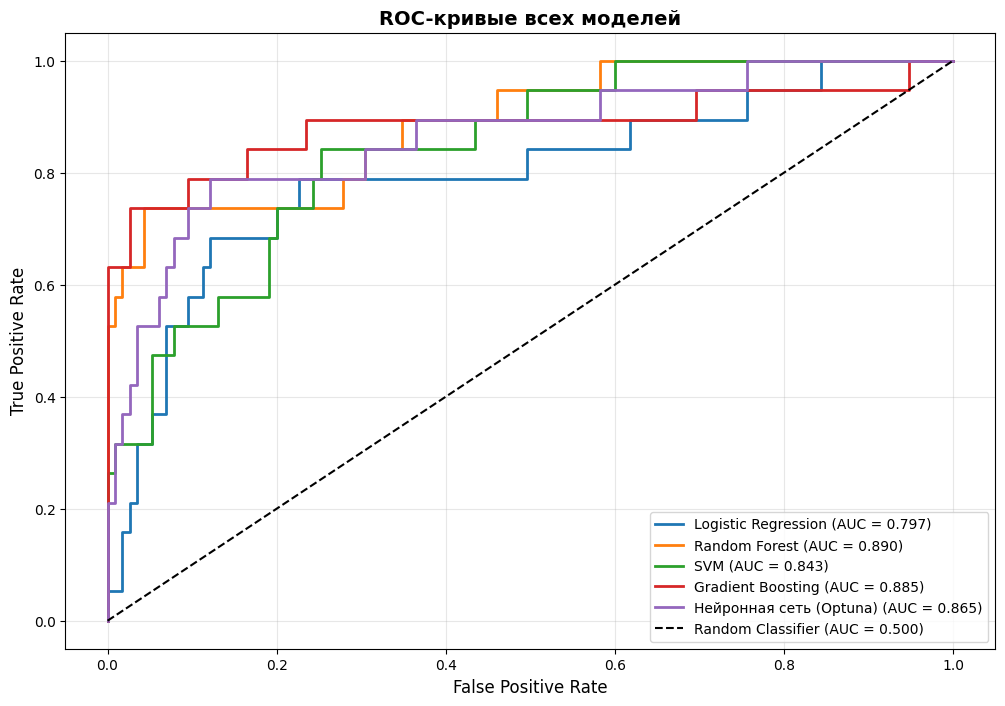

In [32]:
# ROC-кривые для всех моделей
plt.figure(figsize=(12, 8))
for name in results_df['Model']:
    if name == 'Нейронная сеть (Optuna)':
        y_prob = y_prob_nn
    else:
        model = best_models[name]
        if name in ['Logistic Regression', 'SVM']:
            y_prob = model.predict_proba(X_test_scaled)[:, 1]
        else:
            y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.500)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC-кривые всех моделей', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.show()


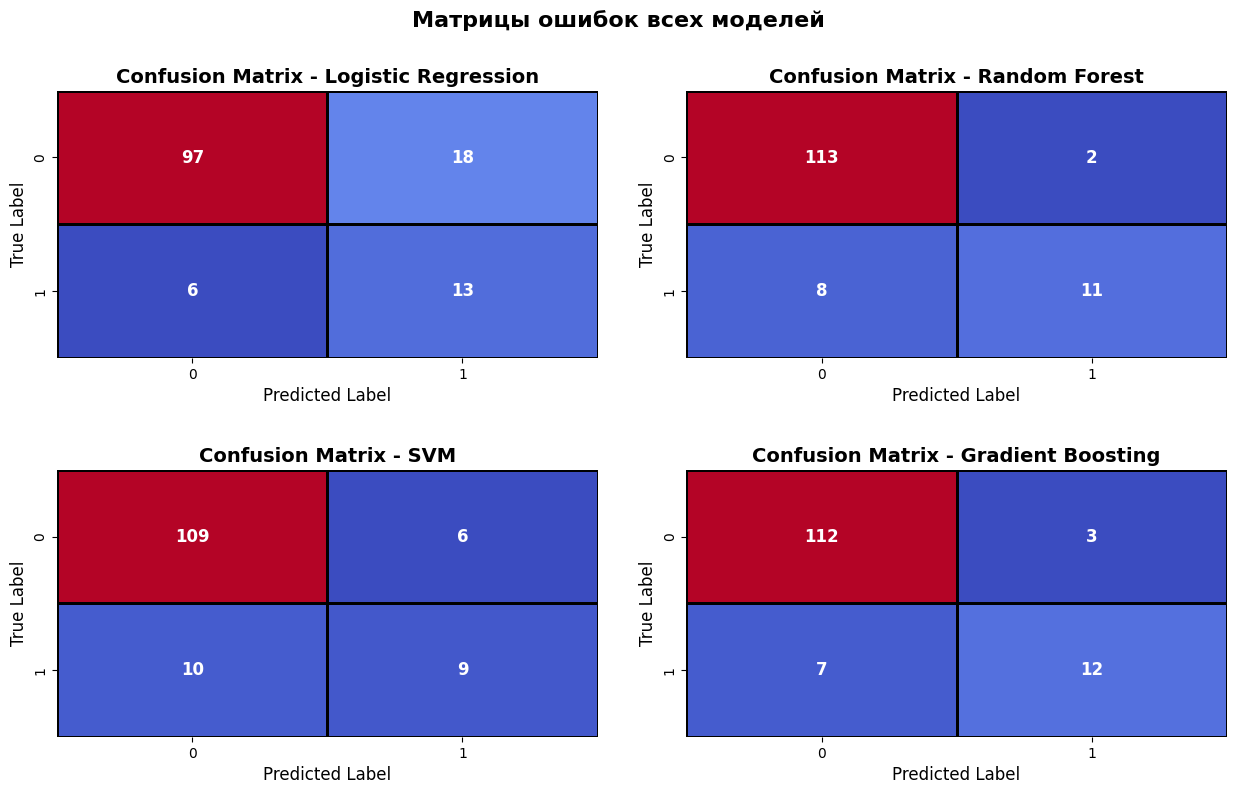

In [33]:

# Матрицы ошибок для всех моделей
plt.figure(figsize=(13, 8))
model_names = list(best_models.keys())

for i, name in enumerate(model_names, 1):
    plt.subplot(2, 2, i)

    model = best_models[name]
    if name == 'Нейронная сеть (Optuna)':
        y_pred = y_pred_nn
    elif name in ['Logistic Regression', 'SVM']:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm', linewidths=2,
                linecolor='black', cbar=False, annot_kws={'size': 12, 'weight': 'bold'})
    plt.title(f'Confusion Matrix - {name}', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)

plt.tight_layout(pad=3.0)
plt.suptitle('Матрицы ошибок всех моделей', fontsize=16, fontweight='bold', y=1.02)
plt.show()

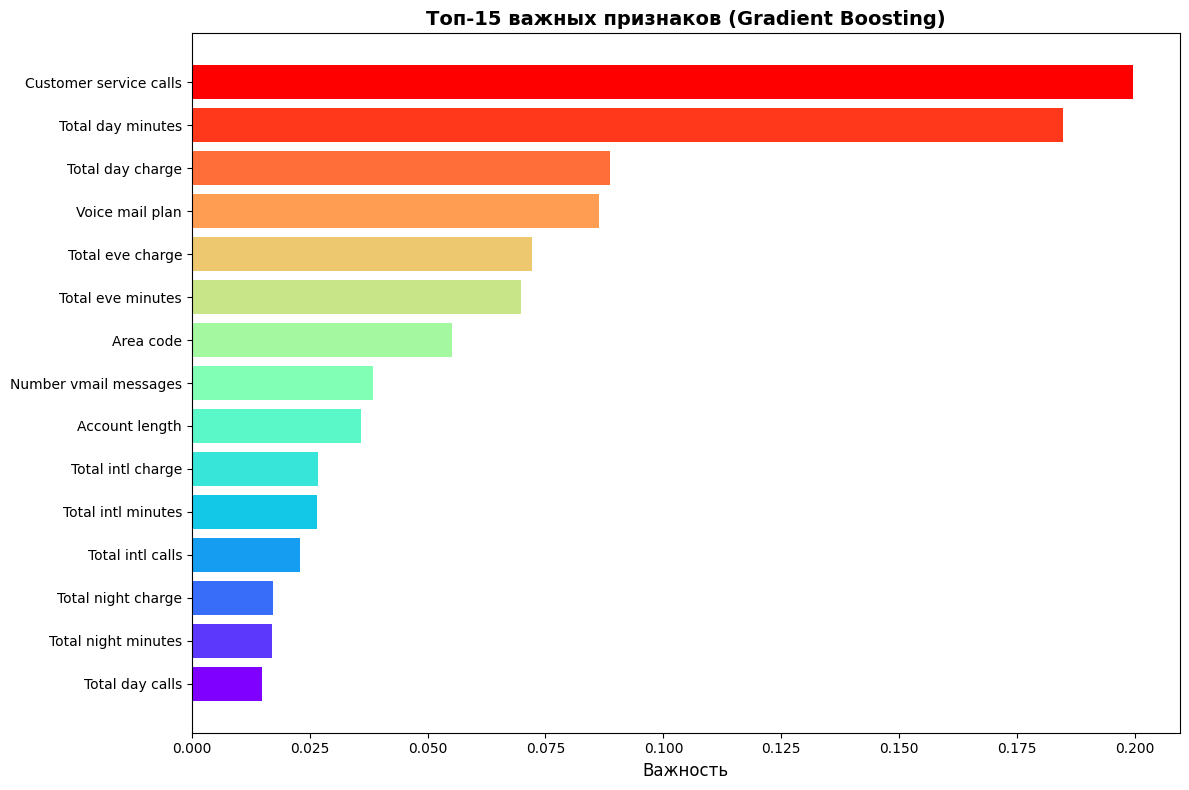

In [34]:
# Анализ важности признаков для лучшей tree-based модели
tree_models = ['Random Forest', 'Gradient Boosting']
best_tree_model_name = None
best_tree_f1 = 0

for name in tree_models:
    if name in best_models and results_df[results_df['Model'] == name]['F1-Score'].iloc[0] > best_tree_f1:
        best_tree_model_name = name
        best_tree_f1 = results_df[results_df['Model'] == name]['F1-Score'].iloc[0]

if best_tree_model_name and hasattr(best_models[best_tree_model_name], 'feature_importances_'):
    plt.figure(figsize=(12, 8))
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': best_models[best_tree_model_name].feature_importances_
    }).sort_values('importance', ascending=True)

    colors = plt.cm.rainbow(np.linspace(0, 1, len(feature_importance[-15:])))

    bars = plt.barh(feature_importance['feature'][-15:], feature_importance['importance'][-15:], color=colors)
    plt.title(f'Топ-15 важных признаков ({best_tree_model_name})', fontsize=14, fontweight='bold')
    plt.xlabel('Важность', fontsize=12)
    plt.tight_layout()
    plt.show()

#Финальные выводы

In [42]:
# ФИНАЛЬНЫЕ ВЫВОДЫ И РЕКОМЕНДАЦИИ
print("ФИНАЛЬНЫЕ ВЫВОДЫ")

# Находим лучшую модель
best_model_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
best_model = best_models[best_model_name]
best_result = results_df.loc[results_df['F1-Score'].idxmax()]

print(f"ЛУЧШАЯ МОДЕЛЬ: {best_model_name}")
print(f"Лучшие метрики:")
print(f"F1-Score: {best_result['F1-Score']:.4f}")
print(f"Recall:   {best_result['Recall']:.4f}")
print(f"Precision: {best_result['Precision']:.4f}")
print(f"Accuracy:  {best_result['Accuracy']:.4f}")
print(f"ROC-AUC:   {best_result['ROC-AUC']:.4f}")

# Сравнение ML и DL
ml_results = results_df[results_df['Model'] != 'Нейронная сеть (Optuna)']
dl_result = results_df[results_df['Model'] == 'Нейронная сеть (Optuna)']

print(f"\nСРАВНЕНИЕ ML vs DEEP LEARNING:")
print(f"   Лучшая ML модель: {ml_results.loc[ml_results['F1-Score'].idxmax(), 'Model']}")
print(f"   F1-Score ML: {ml_results['F1-Score'].max():.4f}")
print(f"   F1-Score DL: {dl_result['F1-Score'].iloc[0]:.4f}")

print(f"\nИтоговый вывод: {best_model_name} показала лучшие результаты. Модель интерпретируема и требует меньше вычислительных ресурсов.")

ФИНАЛЬНЫЕ ВЫВОДЫ
ЛУЧШАЯ МОДЕЛЬ: Gradient Boosting
Лучшие метрики:
F1-Score: 0.7059
Recall:   0.6316
Precision: 0.8000
Accuracy:  0.9254
ROC-AUC:   0.8847

СРАВНЕНИЕ ML vs DEEP LEARNING:
   Лучшая ML модель: Gradient Boosting
   F1-Score ML: 0.7059
   F1-Score DL: 0.6190

Итоговый вывод: Gradient Boosting показала лучшие результаты. Модель интерпретируема и требует меньше вычислительных ресурсов.
